# 13. Train nonlinear models on rich style features

Owner: Gtpatel02. Issue #13. Depends on completed #2 and #9.

## Goal

Build a fixed set of style features that ignore word identity, then train HistGB and ExtraTrees on them. Pick one by training OOF AUROC and confirm on the frozen 2,000. The feature schema, hypothesis, and selection rule are committed before any run.

## Hypothesis and rule (fixed before running)

**Hypothesis.** Style alone carries strong signal. #8 and #9 point at formatting and case, which word TF-IDF drops. We expect the selected model to beat the word C4 handoff (validation 0.941252). Our earlier team repo found blank lines in about two thirds of AI training rows and almost no human rows, so `blank_line_per_line` may dominate. We report importances to check, and treat a dominant formatting feature as a shortcut risk, not as proof of authorship.

**Selection rule.** Three stratified training folds, shuffle seed 42. Pick the candidate with higher pooled out-of-fold AUROC (all 8,000 OOF scores together). Exact tie goes to HistGB, the faster model. The choice is saved before any validation score is computed. Both candidates are refit on 8,000 and both validation scores are reported, but only the saved choice is the handoff.

## Setup

Features are deterministic and learn nothing from labels, so they are computed once per partition before the folds. Only the models learn, and only on fit rows.

To reuse the feature code elsewhere, set `RICH_STYLE_HELPERS_ONLY=1` in the environment, then `%run ./13_rich_style.ipynb`. That defines the schema and `rich_style_features` without fitting.

In [1]:
import json, math, os, re, string, time, unicodedata
from collections import Counter
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
HELPERS_ONLY = os.environ.pop("RICH_STYLE_HELPERS_ONLY", "0") == "1"
get_ipython().run_line_magic("run", "./02_split_metrics.ipynb")
NAME = "13_rich_style"
COMMAND = "uv run --locked jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=1800 notebooks/13_rich_style.ipynb"

## Feature schema

Every rate has a denominator floor of 1, so empty text gives 0, never NaN. Order is fixed by the lists below.

| Group | Features | Denominator |
|---|---|---|
| Log counts | chars, whitespace words, sentences, lines, paragraphs | `log(1 + count)` |
| Vocabulary | unique fraction, hapax fraction, twice-seen fraction, token entropy (bits) | tokens; types; types; none |
| Character rates | uppercase, digit, space, non-ASCII, newline, blank line, tab, punctuation | letters for uppercase; lines for blank line; chars otherwise |
| Shape rates | allcaps, titlecase, long word, short word, contraction, repeated space, URL | whitespace words |
| Line rates | list, heading, indent | lines |
| Other rates | pronoun | tokens |
| Other rates | fragment (sentence under 4 words) | sentences |
| Distributions | mean, std, min, max, q25, median, q75 of word length, sentence words, line words, paragraph words | empty list gives zeros |
| Punctuation counts | each of 32 ASCII punctuation chars, plus en dash, em dash, curly quotes, ellipsis, bullet | raw count |
| Function words | 50 fixed words | tokens |

Definitions: tokens are `\w+` on lowercased text. Sentences are pieces between runs of `[.!?]` that are not blank. Lines split on `\n`, and empty text has no lines; a blank line is empty after strip. Paragraphs split on a blank line. Allcaps needs 2 or more letters, all uppercase. Titlecase is first letter upper, other letters lower. Long word has 7 or more letters, short has 1 to 3. A heading line is non-blank, 8 words or fewer, and does not end in `. ! ? , ; :`. Indent means a non-blank line starting with a space or tab.

In [2]:
TOKEN = re.compile(r"\w+")
SENTENCE_SPLIT = re.compile(r"[.!?]+")
PARAGRAPH_SPLIT = re.compile(r"\n[ \t]*\n")
LIST_LINE = re.compile(r"^\s*(?:[-*\u2022]|\d+[.)])\s")
CONTRACTION = re.compile(r"\w['\u2019]\w")
URL = re.compile(r"https?://|www\.", re.IGNORECASE)
REPEATED_SPACE = re.compile(r" {2,}")
HEADING_END = ".!?,;:"
PRONOUNS = frozenset("i me my mine myself we us our ours ourselves you your yours yourself yourselves".split())
FUNCTION_WORDS = ("the of and to a in is that it for was on with as be by at this are from "
                  "or an but not have has had which they their there been were would could can will "
                  "more also however such these those than then into about very just so").split()
UNICODE_MARKS = {"en_dash": "\u2013", "em_dash": "\u2014", "left_single_quote": "\u2018",
                 "right_single_quote": "\u2019", "left_double_quote": "\u201c",
                 "right_double_quote": "\u201d", "ellipsis": "\u2026", "bullet": "\u2022"}
PUNCT_MARKS = {unicodedata.name(c).lower().replace(" ", "_").replace("-", "_"): c for c in string.punctuation}
PUNCT_MARKS.update(UNICODE_MARKS)
DISTRIBUTIONS = ["word_length", "sentence_words", "line_words", "paragraph_words"]
STATS = ["mean", "std", "min", "max", "q25", "median", "q75"]
FEATURE_NAMES = (
    ["log_chars", "log_words", "log_sentences", "log_lines", "log_paragraphs",
     "unique_fraction", "hapax_fraction", "twice_fraction", "token_entropy",
     "uppercase_per_letter", "digit_per_char", "space_per_char", "nonascii_per_char",
     "newline_per_char", "blank_line_per_line", "tab_per_char", "punct_per_char",
     "allcaps_rate", "titlecase_rate", "long_word_rate", "short_word_rate", "contraction_rate",
     "list_line_rate", "heading_line_rate", "indent_line_rate", "repeated_space_rate",
     "url_rate", "pronoun_rate", "fragment_rate"]
    + [f"{d}_{s}" for d in DISTRIBUTIONS for s in STATS]
    + [f"count_{name}" for name in PUNCT_MARKS]
    + [f"fw_{word}" for word in FUNCTION_WORDS])
require(len(FEATURE_NAMES) == len(set(FEATURE_NAMES)) == 147, "Feature schema must have 147 unique names")
SCHEMA = {"names": FEATURE_NAMES, "punct_marks": {k: f"U+{ord(v):04X}" for k, v in PUNCT_MARKS.items()},
          "function_words": FUNCTION_WORDS, "pronouns": sorted(PRONOUNS), "dtype": "float32",
          "regexes": {"token": TOKEN.pattern, "sentence_split": SENTENCE_SPLIT.pattern,
                      "paragraph_split": PARAGRAPH_SPLIT.pattern, "list_line": LIST_LINE.pattern,
                      "contraction": CONTRACTION.pattern, "url": URL.pattern, "repeated_space": REPEATED_SPACE.pattern}}
SCHEMA_SHA256 = value_hash(SCHEMA)

def summary(values):
    if not values:
        return [0.0] * len(STATS)
    v = np.asarray(values, dtype=float)
    return [v.mean(), v.std(), v.min(), v.max(), *np.quantile(v, [.25, .5, .75])]

def letters_of(word):
    return [c for c in word if c.isalpha()]

def one_text(text):
    text = str(text)
    chars = len(text)
    words = text.split()
    tokens = TOKEN.findall(text.lower())
    sentences = [s for s in SENTENCE_SPLIT.split(text) if s.strip()]
    # Empty text has no lines; "".split("\n") would count one blank line.
    lines = text.split("\n") if text else []
    filled = [line for line in lines if line.strip()]
    paragraphs = [p for p in PARAGRAPH_SPLIT.split(text) if p.strip()]
    counts = Counter(tokens)
    letters = sum(c.isalpha() for c in text)
    n_words, n_tokens, n_types = max(1, len(words)), max(1, len(tokens)), max(1, len(counts))
    n_chars, n_lines, n_sentences = max(1, chars), max(1, len(lines)), max(1, len(sentences))
    word_letters = [letters_of(w) for w in words]
    entropy = -sum(c / n_tokens * math.log2(c / n_tokens) for c in counts.values()) if tokens else 0.0
    row = [
        math.log1p(chars), math.log1p(len(words)), math.log1p(len(sentences)), math.log1p(len(lines)), math.log1p(len(paragraphs)),
        len(counts) / n_tokens, sum(c == 1 for c in counts.values()) / n_types,
        sum(c == 2 for c in counts.values()) / n_types, entropy,
        sum(c.isupper() for c in text) / max(1, letters), sum(c.isdigit() for c in text) / n_chars,
        text.count(" ") / n_chars, sum(ord(c) > 127 for c in text) / n_chars, text.count("\n") / n_chars,
        sum(not line.strip() for line in lines) / n_lines, text.count("\t") / n_chars,
        sum(not c.isalnum() and not c.isspace() for c in text) / n_chars,
        sum(len(w) >= 2 and all(c.isupper() for c in w) for w in word_letters) / n_words,
        sum(len(w) >= 1 and w[0].isupper() and all(c.islower() for c in w[1:]) for w in word_letters) / n_words,
        sum(len(w) >= 7 for w in word_letters) / n_words, sum(1 <= len(w) <= 3 for w in word_letters) / n_words,
        len(CONTRACTION.findall(text)) / n_words,
        sum(bool(LIST_LINE.match(line)) for line in lines) / n_lines,
        sum(len(line.split()) <= 8 and not line.strip().endswith(tuple(HEADING_END)) for line in filled) / n_lines,
        sum(line[:1] in (" ", "\t") for line in filled) / n_lines,
        len(REPEATED_SPACE.findall(text)) / n_words, len(URL.findall(text)) / n_words,
        sum(counts[p] for p in PRONOUNS) / n_tokens,
        sum(len(s.split()) < 4 for s in sentences) / n_sentences,
    ]
    for values in [[len(t) for t in tokens], [len(s.split()) for s in sentences],
                   [len(line.split()) for line in filled], [len(p.split()) for p in paragraphs]]:
        row += summary(values)
    row += [text.count(mark) for mark in PUNCT_MARKS.values()]
    row += [counts[word] / n_tokens for word in FUNCTION_WORDS]
    return row

def rich_style_features(texts):
    matrix = np.asarray([one_text(t) for t in texts], dtype=np.float32)
    require(matrix.shape == (len(texts), len(FEATURE_NAMES)) and np.isfinite(matrix).all(), "Bad style feature matrix")
    return matrix

In [3]:
# Synthetic rows only. These test the feature code, not a model.
toy_texts = ["Hello World. I can't stop!\n\n- one item\n  indented line\nHEADING HERE", "", "   ", "\u2014 \u201cQuoted\u201d\u2026 www.example.com"]
toy = pd.DataFrame(rich_style_features(toy_texts), columns=FEATURE_NAMES)
require(toy.dtypes.eq(np.float32).all() and np.isfinite(toy.to_numpy()).all(), "Dtype or finiteness failed")
require((toy.iloc[1] == 0).all(), "Empty text must give all zeros")
first = toy.iloc[0]
require(first.log_paragraphs == np.float32(math.log1p(2)), "Paragraph split failed")
require(abs(first.blank_line_per_line - 1 / 5) < 1e-6, "Blank line rate failed")
require(abs(first.list_line_rate - 1 / 5) < 1e-6 and abs(first.indent_line_rate - 1 / 5) < 1e-6, "List or indent rate failed")
require(first.count_exclamation_mark == 1 and first.count_apostrophe == 1, "Punctuation counts failed")
require(first.contraction_rate > 0 and first.pronoun_rate > 0, "Contraction or pronoun failed")
fourth = toy.iloc[3]
require(fourth.count_em_dash == 1 and fourth.count_ellipsis == 1 and fourth.count_left_double_quote == 1, "Unicode marks failed")
require(fourth.url_rate > 0, "URL rate failed")
timing_texts = ["Some words here, and more.\nNext line! " * 25] * 500
t0 = time.perf_counter(); rich_style_features(timing_texts); feature_rate = 500 / (time.perf_counter() - t0)
print(f"Synthetic feature checks passed. {len(FEATURE_NAMES)} features, schema {SCHEMA_SHA256[:12]}, about {feature_rate:.0f} texts/s.")

Synthetic feature checks passed. 147 features, schema 3126aec1687a, about 3203 texts/s.


## Checks and config

Recheck the split. Fold ID hashes are saved. Model settings come straight from the issue.

In [4]:
if not HELPERS_ONLY:
    CONFIG = {
        "schema_sha256": SCHEMA_SHA256, "n_features": len(FEATURE_NAMES),
        "cv": {"n_splits": 3, "shuffle": True, "random_state": SEED},
        "selection": "higher pooled OOF AUROC over 3 training folds; exact tie goes to HistGB; saved before validation",
        "candidates": {
            "histgb": {"max_iter": 250, "learning_rate": 0.06, "max_leaf_nodes": 15, "min_samples_leaf": 30,
                       "l2_regularization": 5.0, "early_stopping": False, "random_state": SEED},
            "extratrees": {"n_estimators": 500, "max_features": 0.8, "min_samples_leaf": 3,
                           "random_state": SEED, "n_jobs": 2},
        },
        "threads": "HistGB limited to 1 OpenMP thread; ExtraTrees uses n_jobs=2",
    }
    SOURCE_HASH = value_hash(["".join(c["source"]) for c in json.loads((ROOT / "notebooks/13_rich_style.ipynb").read_text())["cells"]])
    CONFIG["notebook_source_sha256"] = SOURCE_HASH
    RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    START = time.perf_counter()
    parts = load_partitions()
    train, validation = parts["train"], parts["validation"]
    folds = list(StratifiedKFold(**CONFIG["cv"]).split(train.text, train.label))
    CONFIG["fold_id_sha256"] = [{"fit": value_hash(train.id.iloc[a].tolist()), "score": value_hash(train.id.iloc[b].tolist())}
                                for a, b in folds]
    print(f"Train {len(train)}, validation {len(validation)}, folds {len(folds)}")

Train 8000, validation 2000, folds 3


## Run

Save the plan, compute features, run 3 folds per candidate, and save the choice. Only then refit both on 8,000 and score validation.

In [5]:
def make_candidate(name):
    settings = CONFIG["candidates"][name]
    return HistGradientBoostingClassifier(**settings) if name == "histgb" else ExtraTreesClassifier(**settings)

if not HELPERS_ONLY:
    private = ROOT / "artifacts" / NAME / RUN_ID
    private.mkdir(parents=True, exist_ok=False)
    plan_path = ROOT / "results" / NAME / f"{RUN_ID}-plan.json"
    save_new_json(plan_path, {"config": CONFIG, "config_sha256": value_hash(CONFIG), "schema": SCHEMA,
                              "saved_before_fit": True, "split_sha256": parts["split"]["split_sha256"]})
    feature_start = time.perf_counter()
    X_train, X_validation = rich_style_features(train.text), rich_style_features(validation.text)
    feature_seconds = time.perf_counter() - feature_start
    y_train = train.label.to_numpy()
    cv_rows, oof, cv_seconds = [], {}, {}
    for name in CONFIG["candidates"]:
        oof[name] = np.full(len(train), np.nan)
        cv_start = time.perf_counter()
        for fold, (fit_idx, score_idx) in enumerate(folds):
            with threadpool_limits(limits=1, user_api="openmp") if name == "histgb" else threadpool_limits(limits=None):
                model = make_candidate(name).fit(X_train[fit_idx], y_train[fit_idx])
            oof[name][score_idx] = class1_probabilities(model, X_train[score_idx])
            cv_rows.append({"candidate": name, "fold": fold,
                            "auroc": float(roc_auc_score(y_train[score_idx], oof[name][score_idx]))})
        cv_seconds[name] = time.perf_counter() - cv_start
        require(np.isfinite(oof[name]).all(), "OOF scores missing")
    pooled = {name: float(roc_auc_score(y_train, oof[name])) for name in oof}
    selected = "extratrees" if pooled["extratrees"] > pooled["histgb"] else "histgb"
    selection_path = ROOT / "results" / NAME / f"{RUN_ID}-selection.json"
    save_new_json(selection_path, {"selected": selected, "pooled_oof_auroc": pooled,
                                   "fold_auroc": cv_rows, "saved_before_validation": True})
    fits, fit_seconds, val_predictions = {}, {}, {}
    for name in CONFIG["candidates"]:
        fit_start = time.perf_counter()
        with threadpool_limits(limits=1, user_api="openmp") if name == "histgb" else threadpool_limits(limits=None):
            fits[name] = make_candidate(name).fit(X_train, y_train)
        fit_seconds[name] = time.perf_counter() - fit_start
        val_predictions[name] = pd.DataFrame({"id": validation.id.to_numpy(),
                                              "p_ai": class1_probabilities(fits[name], X_validation)})
    scores = {name: {"train": evaluate_predictions(train[["id", "label"]],
                                                   pd.DataFrame({"id": train.id.to_numpy(), "p_ai": class1_probabilities(fits[name], X_train)})),
                     "validation": evaluate_predictions(validation[["id", "label"]], val_predictions[name])}
              for name in fits}
    importances = pd.Series(fits["extratrees"].feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
    run_seconds = time.perf_counter() - START

## Results

Validation was used before (#4 selection, #8 bins, #9 test), so these scores are not unbiased. ExtraTrees impurity importance is a rough, training-fit measure and can favor features with many split points; it shows what the forest leans on, not why.

candidate,extratrees,histgb
fold,,
0,0.996797,0.997970
1,0.997514,0.998606
2,0.995973,0.997613


,candidate,pooled_oof_auroc,train_auroc,validation_auroc,validation_accuracy_at_0_5,cv_seconds,fit_seconds
0,histgb,0.998065,1.000000,0.998105,0.984,3.347328,1.512140
1,extratrees,0.996777,0.999996,0.996831,0.982,11.960502,6.333145


Selected by OOF before validation: histgb. Word C4 handoff validation for reference: 0.941252
Features: 3.8s for 10000 texts; whole run 27.3s


,extratrees_importance
paragraph_words_min,0.1298
paragraph_words_q25,0.1008
unique_fraction,0.0967
paragraph_words_mean,0.0832
paragraph_words_median,0.0826
blank_line_per_line,0.0638
log_paragraphs,0.0485
paragraph_words_q75,0.0483
hapax_fraction,0.0401
token_entropy,0.0329


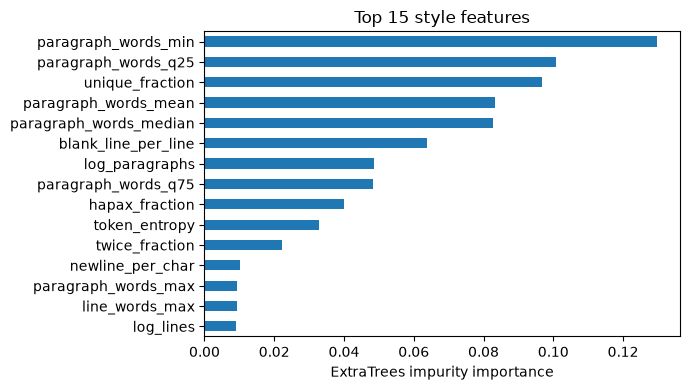

In [6]:
if not HELPERS_ONLY:
    display(pd.DataFrame(cv_rows).pivot(index="fold", columns="candidate", values="auroc").round(6))
    display(pd.DataFrame([{"candidate": name, "pooled_oof_auroc": pooled[name],
                           "train_auroc": scores[name]["train"]["auroc"],
                           "validation_auroc": scores[name]["validation"]["auroc"],
                           "validation_accuracy_at_0_5": scores[name]["validation"]["accuracy_at_0_5"],
                           "cv_seconds": cv_seconds[name], "fit_seconds": fit_seconds[name]} for name in fits]))
    print(f"Selected by OOF before validation: {selected}. Word C4 handoff validation for reference: 0.941252")
    print(f"Features: {feature_seconds:.1f}s for {len(train) + len(validation)} texts; whole run {run_seconds:.1f}s")
    display(importances.head(15).round(4).to_frame("extratrees_importance"))
    fig, ax = plt.subplots(figsize=(7, 4))
    importances.head(15)[::-1].plot.barh(ax=ax)
    ax.set(xlabel="ExtraTrees impurity importance", title="Top 15 style features")
    fig.tight_layout()
    plot_path = ROOT / "results" / NAME / f"{RUN_ID}-importance.png"
    fig.savefig(plot_path, dpi=140)
    plt.show()

### Post-hoc check (added after the first run)

The first run's top importances were paragraph statistics and blank-line rate. Paragraphs split on blank lines, so these may mostly measure whether a blank line exists. This check was added after seeing that result. It does not change the selection. It counts blank-line texts by class and scores validation texts that have no blank line, for both candidates and the word C4 handoff.

In [7]:
if not HELPERS_ONLY:
    def has_blank_line(texts):
        return texts.map(lambda t: bool(PARAGRAPH_SPLIT.search(str(t))))
    blank_counts = {name: {"human": int((has_blank_line(f.text) & (f.label == 0)).sum()), "human_total": int((f.label == 0).sum()),
                           "ai": int((has_blank_line(f.text) & (f.label == 1)).sum()), "ai_total": int((f.label == 1).sum())}
                    for name, f in [("train", train), ("validation", validation)]}
    handoff = json.loads((ROOT / "artifacts/05_char_comparison/latest.json").read_text())
    require(file_hash(ROOT / handoff["validation_predictions"]) == handoff["artifacts"][handoff["validation_predictions"]], "Handoff predictions changed")
    no_blank = validation[~has_blank_line(validation.text)][["id", "label"]]
    subset_scores = {}
    for name, frame in [*val_predictions.items(), ("word_c4_handoff", pd.read_csv(ROOT / handoff["validation_predictions"], dtype={"id": "string"}))]:
        part = no_blank.merge(frame, on="id", validate="one_to_one")
        subset_scores[name] = {"rows": len(part), "ai": int(part.label.sum()), "auroc": float(roc_auc_score(part.label, part.p_ai))}
    display(pd.DataFrame(blank_counts).T)
    display(pd.DataFrame(subset_scores).T)

,human,human_total,ai,ai_total
train,16,4000,2629,4000
validation,1,1000,676,1000


,rows,ai,auroc
histgb,1323.0,324.0,0.994692
extratrees,1323.0,324.0,0.991246
word_c4_handoff,1323.0,324.0,0.950889


## Takeaway

- Tried: 147 style features with no word identity. HistGB vs ExtraTrees on 3 training folds; the choice was saved before validation.
- Found: HistGB selected (pooled OOF 0.998065 vs 0.996777). Validation 0.998105, vs 0.941252 for the word C4 handoff. Top importances are paragraph stats and blank-line rate. Post-hoc: blank lines appear in 16 of 4,000 human training rows and 2,629 of 4,000 AI rows. On the 1,323 validation texts with no blank line, HistGB still scores 0.994692 (word C4 0.950889).
- Next: blank-line formatting is a likely shortcut on unfamiliar text. #12 stress-tests formatting and #14 tests augmentation. HistGB is the handoff for #14 and #15.

Guess, not tested: on texts without blank lines, line-break and vocabulary features still separate the classes, but these may also reflect how the dataset was built rather than authorship.

## Save

Both fitted models, the schema, and validation probabilities stay under ignored `artifacts/13_rich_style/`. A private pointer `artifacts/13_rich_style/latest.json` names the selected model for #14, #15, and #17. The safe record keeps fold scores, both candidates, the selection, top importances, and timings.

In [8]:
if not HELPERS_ONLY:
    artifacts = [plan_path, selection_path, plot_path]
    reload_difference = {}
    for name in fits:
        model_path = private / f"{name}.joblib"
        joblib.dump(fits[name], model_path)
        # ExtraTrees with n_jobs=2 sums tree votes in thread order, so the last bits can differ between calls.
        reload_difference[name] = float(np.max(np.abs(class1_probabilities(joblib.load(model_path), X_validation)
                                                      - val_predictions[name].p_ai.to_numpy())))
        require(reload_difference[name] <= 1e-12, "Reloaded model changed predictions")
        prediction_path = private / f"{name}_validation.csv"
        val_predictions[name].to_csv(prediction_path, index=False)
        artifacts += [model_path, prediction_path]
    schema_path = private / "schema.json"
    save_new_json(schema_path, SCHEMA)
    artifacts.append(schema_path)
    metrics = {"validation_auroc": scores[selected]["validation"]["auroc"], "selected": selected,
               "pooled_oof_auroc": pooled, "fold_auroc": cv_rows,
               "candidates": {name: {"train_auroc": scores[name]["train"]["auroc"],
                                     "validation_auroc": scores[name]["validation"]["auroc"],
                                     "validation_accuracy_at_0_5": scores[name]["validation"]["accuracy_at_0_5"],
                                     "cv_seconds": cv_seconds[name], "fit_seconds": fit_seconds[name]} for name in fits},
               "top_importances": {k: float(v) for k, v in importances.head(15).items()},
               "feature_seconds": feature_seconds,
               "posthoc_blank_line_counts": blank_counts, "posthoc_no_blank_line_validation": subset_scores,
               "max_reload_difference": reload_difference}
    CONFIG["extra_versions"] = {name: importlib.metadata.version(name) for name in ["joblib", "matplotlib", "threadpoolctl"]}
    record_path = record_run(NAME, COMMAND, CONFIG, SEED, len(train), len(validation), metrics,
                             time.perf_counter() - START, artifacts=artifacts)
    pointer = {"result": str(record_path.relative_to(ROOT)), "result_sha256": file_hash(record_path),
               "split_sha256": parts["split"]["split_sha256"], "selected": selected,
               "model": str((private / f"{selected}.joblib").relative_to(ROOT)),
               "schema": str(schema_path.relative_to(ROOT)), "schema_sha256": SCHEMA_SHA256,
               "feature_interface": "class1_probabilities(joblib.load(model), rich_style_features(texts))",
               "artifacts": {str(Path(p).relative_to(ROOT)): file_hash(p) for p in artifacts}}
    pointer_path = ROOT / "artifacts" / NAME / "latest.json"
    pointer_path.write_text(json.dumps(pointer, indent=2, sort_keys=True) + "\n")
    print(f"Saved {record_path.relative_to(ROOT)}")

Saved results/13_rich_style/20261110T195146556937Z.json
